# CSAD 模型（基于板块中地位）

**用于构建羊群效应因子的行为金融模型**

① 每个月末，提取当前可交易股票过去 120 个交易日的涨跌幅数据，计算目标股票 $S_*$ 与其他股票（不活跃交易日不超过 20 天）之间的日涨跌幅相关系数；

② 选取与 $S_*$ 相关系数最大的 9 只股票，连同 $S_*$ 一起构成一个包含 10 只股票的“小型”板块：

$$
S_i, \quad i = 1, 2, \dots, 10
$$

③ 以 $S_*$ 为中心股票，计算该板块过去 120 个交易日的横截面绝对偏差（CSAD）：

$$
\text{CSAD}_t = \frac{1}{10} \sum_{i=1}^{10} \left| r_{i,t} - r_{*,t} \right|
$$

其中，$r_{i,t}$ 为板块内第 $i$ 只股票在交易日 $t$ 的收益率，$r_{*,t}$ 为中心股票 $S_*$ 在交易日 $t$ 的收益率。

④ 对 CSAD 进行时序标准化，并计算过去 20 个交易日的均值，作为羊群效应因子：

$$
Z_{jt} = \frac{\text{CSAD}_{jt} - \mu_{\text{CSAD}_j}}{\sigma_{\text{CSAD}_j}}
$$$$
f_{jt} = -\frac{1}{20} \sum_{k=1}^{20} Z_{j,t-k+1}
$$

其中，$j$ 表示第 $j$ 个“小型”板块，$\mu_{\text{CSAD}_j}$ 和 $\sigma_{\text{CSAD}_j}$ 分别为该板块 CSAD 在样本期内的均值和标准差，$Z_{jt}$ 为标准化后的 CSAD，$f_{jt}$ 为最终的羊群效应因子。

## 因子逻辑说明

CSAD 利用股票收益在横截面上的分散度来衡量市场羊群效应的强弱。为使因子对个股具备选股能力，该模型将与目标个股走势最为相近的股票组成“小型”板块，借助该小板块上的羊群效应强弱来近似反映该股票近期的关注度变化。

与基于板块均值的 CSAD 模型不同，本模型以中心股票 $S_*$ 的收益为参照基准，计算板块内其他股票相对于该中心股票的偏离程度。因子值 $f_{jt}$ 越大（由于负号处理，对应近期 CSAD 显著偏低），表明中心股票收益越接近板块内其他股票的中位数水平，板块近期的羊群效应越强，该板块受市场关注的程度提升越明显，未来收益预期也越高。

数据：日度收盘价

In [1]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def _download_returns_wide(order_book_ids, price_dates, batch_size=500):
    """
    分批下载收盘价与成交量，返回“日期 × 股票”的日收益率宽表。

    停牌或无成交日的收益率会保留为 NaN。
    """
    return_parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(
            batch=batch,
            price_dates=price_dates,
        )

        if close is None:
            continue

        return_parts.append(_get_returns(close, volume))

    if not return_parts:
        raise RuntimeError("未取得有效价格数据。")

    returns = pd.concat(return_parts, axis=1)

    return (
        returns
        .reindex(index=price_dates[1:], columns=order_book_ids)
        .sort_index()
    )

def _calculate_center_board_csad(
    board_returns,
    center_stock,
    min_group_active=10,
):
    """
    以中心股票收益为参照计算板块 CSAD。

    CSAD_t = mean_i(|r_i,t - r_center,t|)

    中心股票自身的偏差为 0，因此在 10 只股票都有效时，
    分母自然就是原公式中的 10。
    """
    center_return = board_returns[center_stock]

    active_count = board_returns.notna().sum(axis=1)

    csad = (
        board_returns.sub(center_return, axis=0)
        .abs()
        .mean(axis=1, skipna=True)
    )

    return csad.where(active_count >= min_group_active)

def calculate_center_board_csad(
    start_date,
    end_date,
    candidate_ids=None,
    peer_universe_ids=None,
    corr_window=120,
    max_inactive_days=20,
    group_size=10,
    zscore_window=120,
    smooth_window=20,
    min_group_active=10,
    batch_size=500,
):
    """
    基于“小型”板块的 CSAD 羊群效应因子。

    返回
    ----
    DataFrame
        MultiIndex：date、order_book_id
        Column：SMALL_BOARD_CSAD

    因子值越大：
        表示近期板块 CSAD 越低、股票走势越趋同、羊群效应越强。
    """
    if group_size < 2:
        raise ValueError("group_size 至少为 2。")

    if min_group_active > group_size:
        raise ValueError("min_group_active 不能大于 group_size。")

    if corr_window <= max_inactive_days:
        raise ValueError("corr_window 必须大于 max_inactive_days。")

    # 第一个输出日需要：
    # 1）120 日相关性历史；
    # 2）120 日 CSAD 标准化历史；
    # 3）20 日 Z 值平滑历史；
    # 4）预留一个月，确保存在上一个月末的分组。
    required_lookback = (
        corr_window + zscore_window + smooth_window + 25
    )

    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=required_lookback,
    )

    candidate_ids = _get_ids(candidate_ids)
    peer_universe_ids = _get_ids(peer_universe_ids)

    # 目标股票必须包含在找同伴的股票池中。
    peer_universe_ids = list(dict.fromkeys(
        peer_universe_ids + candidate_ids
    ))

    # 日期 × 股票 的收益率宽表。
    returns = _download_returns_wide(
        order_book_ids=peer_universe_ids,
        price_dates=price_dates,
        batch_size=batch_size,
    )

    work_dates = returns.index
    target_date_set = set(target_dates)

    factor_wide = pd.DataFrame(
        np.nan,
        index=target_dates,
        columns=candidate_ids,
    )

    # 找到每个月最后一个交易日。
    month_end_dates = pd.DatetimeIndex(
        pd.Series(
            work_dates,
            index=work_dates.to_period("M"),
        )
        .groupby(level=0)
        .max()
        .values
    )

    min_corr_observations = corr_window - max_inactive_days

    for rebalance_pos, rebalance_date in enumerate(month_end_dates):
        date_pos = work_dates.get_loc(rebalance_date)

        # 没有足够的 120 日收益率历史时，无法建立小型板块。
        if date_pos + 1 < corr_window:
            continue

        correlation_returns = returns.iloc[
            date_pos - corr_window + 1:date_pos + 1
        ]

        valid_count = correlation_returns.notna().sum(axis=0)

        eligible_ids = valid_count[
            valid_count >= min_corr_observations
        ].index.tolist()

        if len(eligible_ids) < group_size:
            continue

        # 只用近期活跃且窗口内缺失不超过 max_inactive_days 的股票计算相关性。
        corr_matrix = correlation_returns[
            eligible_ids
        ].corr(min_periods=min_corr_observations)

        current_candidates = [
            stock for stock in candidate_ids
            if (
                stock in eligible_ids
                and pd.notna(returns.loc[rebalance_date, stock])
            )
        ]

        # 本月末形成的板块，持续到下个月末前。
        if rebalance_pos < len(month_end_dates) - 1:
            next_rebalance_date = month_end_dates[rebalance_pos + 1]
            effective_dates = work_dates[
                (work_dates >= rebalance_date)
                & (work_dates < next_rebalance_date)
            ]
        else:
            effective_dates = work_dates[
                work_dates >= rebalance_date
            ]

        output_dates = [
            date for date in effective_dates
            if date in target_date_set
        ]

        if not output_dates:
            continue

        for stock in current_candidates:
            peer_corr = (
                corr_matrix[stock]
                .drop(index=stock, errors="ignore")
                .dropna()
                .sort_values(ascending=False)
            )

            peers = peer_corr.head(group_size - 1).index.tolist()

            if len(peers) < group_size - 1:
                continue

            small_board = [stock] + peers
            board_returns = returns[small_board]

            # 以目标股票 stock 为中心收益基准计算 CSAD。
            csad = _calculate_center_board_csad(
                board_returns=board_returns,
                center_stock=stock,
                min_group_active=min_group_active,
            )

            # 使用截至当天的滚动均值与标准差标准化。
            rolling_mean = csad.rolling(
                window=zscore_window,
                min_periods=zscore_window,
            ).mean()

            rolling_std = csad.rolling(
                window=zscore_window,
                min_periods=zscore_window,
            ).std(ddof=0)

            zscore = (
                (csad - rolling_mean)
                / rolling_std.replace(0, np.nan)
            )

            # 加负号：CSAD 越低，因子越高，代表羊群越强。
            factor_series = -zscore.rolling(
                window=smooth_window,
                min_periods=smooth_window,
            ).mean()

            factor_wide.loc[
                output_dates, stock
            ] = factor_series.reindex(output_dates).values

    return _stack_factor(factor_wide, "CENTER_BOARD_CSAD")

In [4]:
# 沪深300成分股

stock_pool = index_components(
    "000300.XSHG",
    date="2025-12-31",
)

center_board_csad_panel = calculate_center_board_csad(
    start_date="2020-01-01",
    end_date="2025-12-31",
    candidate_ids=stock_pool,
    peer_universe_ids=stock_pool,
    corr_window=120,
    max_inactive_days=20,
    group_size=10,
    zscore_window=120,
    smooth_window=20,
    min_group_active=10,
)

center_board_csad_panel.head()

# CENTER_BOARD_CSAD 越高，表示目标股票与其 9 个高相关同伴的近期收益偏离越低，即该股票越处于板块共同交易节奏的中心。

CENTER_BOARD_CSAD
date       order_book_id                   
2020-01-02 002027.XSHE            -0.255644
           000999.XSHE             0.222663
           600010.XSHG             0.027459
           601009.XSHG             0.405007
           001965.XSHE            -0.266832

In [2]:
# 计算量非常大

all_a_parts = []

for year in [2020, 2021, 2022, 2023, 2024, 2025]:
    factor_part = calculate_center_board_csad(
        start_date="{}-01-01".format(year),
        end_date="{}-12-31".format(year),
        candidate_ids=None,
        peer_universe_ids=None,
        corr_window=120,
        max_inactive_days=20,
        group_size=10,
        zscore_window=120,
        smooth_window=20,
        min_group_active=10
    )
    print(1)

    all_a_parts.append(factor_part)

center_board_csad_panel = pd.concat(all_a_parts).sort_index()

1
1
1
1


In [3]:
center_board_csad_panel

CENTER_BOARD_CSAD
date       order_book_id                   
2020-01-02 000001.XSHE             0.411898
           000002.XSHE            -0.388180
           000005.XSHE             0.249578
           000006.XSHE             0.834139
           000008.XSHE            -0.177469
...                                     ...
2025-12-31 688793.XSHG            -0.433781
           688798.XSHG             0.518054
           688799.XSHG             0.627763
           688800.XSHG            -0.162288
           689009.XSHG             0.334886

[5102520 rows x 1 columns]

In [4]:
center_board_csad_panel_df = center_board_csad_panel.unstack(level="order_book_id")
center_board_csad_panel_df

CENTER_BOARD_CSAD                                      \
order_book_id       000001.XSHE 000002.XSHE 000004.XSHE 000005.XSHE   
date                                                                  
2020-01-02             0.411898   -0.388180         NaN    0.249578   
2020-01-03             0.322883   -0.452286         NaN    0.237699   
2020-01-06             0.367806   -0.510713         NaN    0.263799   
2020-01-07             0.415005   -0.369530         NaN    0.236151   
2020-01-08             0.347296   -0.485286         NaN    0.225074   
...                         ...         ...         ...         ...   
2025-12-25             0.090279   -0.589138   -0.462995         NaN   
2025-12-26             0.044005   -0.498008   -0.362081         NaN   
2025-12-29             0.107920   -0.365254   -0.227810         NaN   
2025-12-30             0.119843   -0.387187   -0.263417         NaN   
2025-12-31             0.239394   -0.212848    0.027699         NaN   

                                                                           \
order_book_id 000006.XSHE 000007.XSHE 000008.XSHE 000009.XSHE 000010.XSHE   
date                                                                        
2020-01-02       0.834139         NaN   -0.177469         NaN    0.380431   
2020-01-03       0.764870         NaN   -0.048014         NaN    0.428667   
2020-01-06       0.748655         NaN    0.018923         NaN    0.463290   
2020-01-07       0.694889         NaN    0.202402         NaN    0.381835   
2020-01-08       0.688005         NaN    0.159682         NaN    0.334588   
...                   ...         ...         ...         ...         ...   
2025-12-25       0.142555   -1.214911   -0.263106    0.482274    0.455278   
2025-12-26       0.138638   -1.247507   -0.265220    0.475277    0.454288   
2025-12-29       0.222378   -0.889831   -0.331930    0.525470    0.452599   
2025-12-30       0.261203   -0.974223   -0.297586    0.478316    0.441363   
2025-12-31       0.462350   -0.572059   -0.052619    0.602931    0.532938   

                           ...                                      \
order_book_id 000011.XSHE  ... 688787.XSHG 688788.XSHG 688789.XSHG   
date                       ...                                       
2020-01-02       0.606807  ...         NaN         NaN         NaN   
2020-01-03       0.565456  ...         NaN         NaN         NaN   
2020-01-06       0.550881  ...         NaN         NaN         NaN   
2020-01-07       0.514836  ...         NaN         NaN         NaN   
2020-01-08       0.505669  ...         NaN         NaN         NaN   
...                   ...  ...         ...         ...         ...   
2025-12-25       0.448139  ...    0.296728         NaN   -0.101223   
2025-12-26       0.456002  ...    0.180005         NaN   -0.086461   
2025-12-29       0.514621  ...    0.196609         NaN   -0.043660   
2025-12-30       0.514021  ...    0.194903         NaN   -0.087479   
2025-12-31       0.572489  ...    0.182910   -0.007795    0.459188   

                                                                           \
order_book_id 688793.XSHG 688798.XSHG 688799.XSHG 688800.XSHG 688819.XSHG   
date                                                                        
2020-01-02            NaN         NaN         NaN         NaN         NaN   
2020-01-03            NaN         NaN         NaN         NaN         NaN   
2020-01-06            NaN         NaN         NaN         NaN         NaN   
2020-01-07            NaN         NaN         NaN         NaN         NaN   
2020-01-08            NaN         NaN         NaN         NaN         NaN   
...                   ...         ...         ...         ...         ...   
2025-12-25      -0.010879    0.196877    0.622989   -0.288581         NaN   
2025-12-26      -0.502120    0.210882    0.593996   -0.305684         NaN   
2025-12-29      -0.468916    0.384024    0.597425   -0.299427         NaN   
2025-12-30      -0.503592    0.4616

In [8]:
center_board_csad_panel_df.to_csv('center_board_csad_panel.csv', index=True)
# center_board_csad_panel_df = pd.read_csv('center_board_csad_panel.csv', index_col=0)

你的实现与公式基本一致，且 min_group_active=10 时分母确实是 10。需要注意两点：
1. 因子在月末用到了当天收盘后的收益与相关系数，因此只能用于 下一交易日 的交易；回测时应整体 shift(1)。
2. “中心股票接近板块中位数”是近似解释。该指标实际衡量的是中心股票与全部 10 只股票的平均绝对收益偏离；只有板块整体也较集中时，低 CSAD 才更明确代表羊群效应。
另外，你的代码使用的是“截至当日的 120 日滚动标准化”，这是避免未来函数的正确做法；说明文字中的“样本期均值和标准差”建议改成“截至当日的滚动窗口均值和标准差”。

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rqdatac import get_trading_dates


def check_center_board_csad_output(
    panel,
    start_date="2020-01-01",
    end_date="2025-12-31",
    factor_name="CENTER_BOARD_CSAD",
):
    """检查中心股票基准的小型板块 CSAD 因子输出。"""

    if not isinstance(panel.index, pd.MultiIndex) or panel.index.nlevels != 2:
        raise ValueError("panel 必须是两层 MultiIndex：(date, order_book_id)。")

    if factor_name not in panel.columns:
        raise ValueError("未找到因子列：{}".format(factor_name))

    target_dates = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date,
            end_date=end_date,
        )
    )

    data = panel[[factor_name]].copy()
    data.index = data.index.set_names(["date", "order_book_id"])
    data = data.reset_index()

    data["date"] = pd.to_datetime(data["date"])
    data = data[
        (data["date"] >= target_dates.min())
        & (data["date"] <= target_dates.max())
    ].copy()

    data["_value"] = pd.to_numeric(
        data[factor_name],
        errors="coerce",
    )

    duplicate_count = data.duplicated(
        ["date", "order_book_id"]
    ).sum()

    missing_count = data["_value"].isna().sum()

    finite_mask = np.isfinite(data["_value"].fillna(0.0))
    inf_count = (
        data["_value"].notna()
        & (~finite_mask)
    ).sum()

    valid = data[
        data["_value"].notna()
        & np.isfinite(data["_value"])
    ].copy()

    values = valid["_value"]

    daily = valid.groupby("date")["_value"].agg(
        ["count", "mean", "std", "min", "median", "max"]
    )

    daily["P01"] = valid.groupby("date")["_value"].quantile(0.01)
    daily["P05"] = valid.groupby("date")["_value"].quantile(0.05)
    daily["P95"] = valid.groupby("date")["_value"].quantile(0.95)
    daily["P99"] = valid.groupby("date")["_value"].quantile(0.99)

    daily = daily.reindex(target_dates)
    daily["count"] = daily["count"].fillna(0).astype(int)
    daily["year"] = daily.index.year

    yearly_max_count = daily.groupby("year")["count"].transform("max")
    daily["relative_coverage"] = daily["count"].div(
        yearly_max_count.replace(0, np.nan)
    )

    daily = daily.rename(columns={
        "count": "因子股票数",
        "mean": "均值",
        "std": "标准差",
        "min": "最小值",
        "median": "中位数",
        "max": "最大值",
        "relative_coverage": "相对覆盖率",
    })

    stock_days = valid.groupby("order_book_id").size()

    # 检查连续交易日的因子跳变，避免把长期停牌后的间隔误当作日变化。
    ordered = valid.sort_values(
        ["order_book_id", "date"]
    ).copy()

    ordered["_previous_value"] = ordered.groupby(
        "order_book_id"
    )["_value"].shift(1)

    ordered["_previous_date"] = ordered.groupby(
        "order_book_id"
    )["date"].shift(1)

    date_position = pd.Series(
        np.arange(len(target_dates)),
        index=target_dates,
    )

    ordered["_position"] = ordered["date"].map(date_position)
    ordered["_previous_position"] = ordered.groupby(
        "order_book_id"
    )["_position"].shift(1)

    ordered["_continuous"] = (
        ordered["_position"] - ordered["_previous_position"]
    ).eq(1)

    ordered["_abs_change"] = (
        ordered["_value"] - ordered["_previous_value"]
    ).abs().where(ordered["_continuous"])

    # 每月最后一个交易日是代码中重新形成板块的日期。
    rebalance_dates = pd.DatetimeIndex(
        pd.Series(
            target_dates,
            index=target_dates.to_period("M"),
        ).groupby(level=0).max().values
    )

    ordered["_is_rebalance_date"] = ordered["date"].isin(
        rebalance_dates
    )

    first_dates_each_year = []
    first_three_dates_each_year = []

    for year in sorted(pd.Index(target_dates.year).unique()):
        year_dates = target_dates[target_dates.year == year]
        first_dates_each_year.append(year_dates[0])
        first_three_dates_each_year.extend(year_dates[:3].tolist())

    ordered["_is_year_start"] = ordered["date"].isin(
        first_dates_each_year
    )

    continuous_change = ordered["_abs_change"].dropna()
    rebalance_change = ordered.loc[
        ordered["_is_rebalance_date"],
        "_abs_change",
    ].dropna()

    year_start_change = ordered.loc[
        ordered["_is_year_start"],
        "_abs_change",
    ].dropna()

    def safe_quantile(series, q):
        series = series.dropna()
        if len(series) == 0:
            return np.nan
        return series.quantile(q)

    summary = pd.DataFrame([
        ["目标交易日数", len(target_dates), ""],
        ["有至少一个因子值的交易日数",
         int((daily["因子股票数"] > 0).sum()),
         "应接近目标交易日数"],
        ["完全无输出交易日数",
         int((daily["因子股票数"] == 0).sum()),
         "应为 0"],
        ["实际有效观测数", len(valid), ""],
        ["覆盖股票数", valid["order_book_id"].nunique(), ""],
        ["重复 date-stock", duplicate_count, "应为 0"],
        ["显式缺失值", missing_count, "最终 stack 后通常应为 0"],
        ["无穷值（inf/-inf）", inf_count, "应为 0"],
        ["每日因子股票数均值", daily["因子股票数"].mean(), ""],
        ["每日因子股票数 P05",
         daily["因子股票数"].quantile(0.05),
         "检查低覆盖交易日"],
        ["相对覆盖率 P05",
         safe_quantile(daily["相对覆盖率"], 0.05),
         "建议大于 0.80"],
        ["单股有效天数 P05",
         stock_days.quantile(0.05),
         "新股、停牌股或无法形成完整板块的股票通常较低"],
        ["因子均值", values.mean(), "滚动 Z 分数平滑后通常接近 0，但不要求严格为 0"],
        ["因子标准差", values.std(), ""],
        ["负值占比", (values < 0).mean(), "正负值均合理"],
        ["零值占比", (values == 0).mean(), "允许出现，但通常较少"],
        ["最小值", values.min(), "因子可为负"],
        ["P01", values.quantile(0.01), ""],
        ["中位数", values.median(), ""],
        ["P99", values.quantile(0.99), ""],
        ["最大值", values.max(), "因子可为正"],
        ["|因子值| > 3 的观测数",
         int((values.abs() > 3).sum()),
         "用于复核极端低 CSAD 板块"],
        ["|因子值| > 4 的观测数",
         int((values.abs() > 4).sum()),
         "优先检查滚动标准差过小或异常板块"],
        ["连续交易日变化绝对值 P99",
         safe_quantile(continuous_change, 0.99),
         "检查因子日度稳定性"],
        ["月末重新分组日变化绝对值 P99",
         safe_quantile(rebalance_change, 0.99),
         "显著高于普通日时，检查月末换组影响"],
        ["年度首日变化绝对值 P99",
         safe_quantile(year_start_change, 0.99),
         "检查按年度分段计算是否造成跳变"],
    ], columns=["指标", "数值", "判断"]).set_index("指标")

    print("总体统计：")
    display(summary)

    print("\n最近 5 个交易日横截面统计：")
    display(daily.tail())

    print("\n各年度最前 3 个交易日统计：")
    display(daily.loc[first_three_dates_each_year])

    print("\n因子值最大的 20 条记录：")
    display(
        valid.sort_values("_value", ascending=False)
        [["date", "order_book_id", factor_name]]
        .head(20)
    )

    print("\n因子值最小的 20 条记录：")
    display(
        valid.sort_values("_value", ascending=True)
        [["date", "order_book_id", factor_name]]
        .head(20)
    )

    return summary, daily


center_board_csad_summary, center_board_csad_daily = (
    check_center_board_csad_output(
        center_board_csad_panel,
        start_date="2020-01-01",
        end_date="2025-12-31",
        factor_name="CENTER_BOARD_CSAD",
    )
)

总体统计：


,数值,判断
指标,,
目标交易日数,1.455000e+03,
有至少一个因子值的交易日数,1.455000e+03,应接近目标交易日数
完全无输出交易日数,0.000000e+00,应为 0
实际有效观测数,5.102520e+06,
覆盖股票数,5.325000e+03,
重复 date-stock,0.000000e+00,应为 0
显式缺失值,0.000000e+00,最终 stack 后通常应为 0
无穷值（inf/-inf）,0.000000e+00,应为 0
每日因子股票数均值,3.506887e+03,



最近 5 个交易日横截面统计：


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99,year,相对覆盖率
2025-12-25,4043,-0.161200,0.531904,-2.611487,-0.046319,1.040082,-1.813070,-1.202555,0.484629,0.660052,2025,0.920747
2025-12-26,4048,-0.167085,0.534128,-2.907525,-0.051434,1.054668,-1.832847,-1.215371,0.486713,0.651154,2025,0.921886
2025-12-29,4044,-0.165559,0.536837,-2.812749,-0.048113,1.046100,-1.846959,-1.216212,0.490212,0.645384,2025,0.920975
2025-12-30,4062,-0.169092,0.531479,-2.767823,-0.062615,1.013251,-1.857720,-1.208577,0.492219,0.644115,2025,0.925074
2025-12-31,4065,0.061685,0.459924,-2.494798,0.171525,1.126500,-1.531789,-0.868712,0.597763,0.748214,2025,0.925757



各年度最前 3 个交易日统计：


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99,year,相对覆盖率
2020-01-02,2317,0.130390,0.383396,-1.837607,0.209524,0.880955,-1.154174,-0.617421,0.603624,0.719482,2020,0.929775
2020-01-03,2309,0.096746,0.391443,-2.079327,0.174832,0.886600,-1.134155,-0.658724,0.578957,0.701669,2020,0.926565
2020-01-06,2302,0.055786,0.404543,-2.254191,0.130931,0.870176,-1.216191,-0.728113,0.563783,0.678286,2020,0.923756
2021-01-04,2362,-0.014934,0.401470,-2.094768,0.060105,1.001284,-1.295877,-0.793941,0.505283,0.632772,2021,0.726322
2021-01-05,2384,-0.050904,0.406109,-2.103282,0.019120,0.984978,-1.271249,-0.829124,0.489297,0.616990,2021,0.733087
2021-01-06,2389,-0.094335,0.410809,-2.261324,-0.031088,0.943906,-1.314682,-0.890713,0.458170,0.577641,2021,0.734625
2022-01-04,3081,0.071240,0.472320,-2.551617,0.168047,1.059535,-1.478965,-0.837296,0.647128,0.818191,2022,0.825121
2022-01-05,3101,0.046621,0.493447,-2.658378,0.156511,1.039708,-1.600123,-0.933439,0.641888,0.824869,2022,0.830477
2022-01-06,3107,0.022245,0.514736,-2.772955,0.135873,1.010279,-1.627338,-1.011739,0.640714,0.835194,2022,0.832084
2023-01-03,3621,0.146997,0.456765,-2.325938,0.255377,0.971831,-1.397428,-0.764474,0.680614,0.819031,2023,0.839166



因子值最大的 20 条记录：


,date,order_book_id,CENTER_BOARD_CSAD
1150051,2021-12-01,601898.XSHG,1.246002
1153012,2021-12-02,601898.XSHG,1.241677
1147116,2021-11-30,601898.XSHG,1.235744
1306662,2022-02-16,300228.XSHE,1.234056
1771649,2022-09-05,603229.XSHG,1.231978
1985547,2022-12-07,600025.XSHG,1.231621
1147476,2021-11-30,603980.XSHG,1.230144
1764845,2022-09-01,603229.XSHG,1.220869
1303320,2022-02-15,300228.XSHE,1.219778
1775057,2022-09-06,603229.XSHG,1.216601



因子值最小的 20 条记录：


,date,order_book_id,CENTER_BOARD_CSAD
3091752,2024-01-24,603333.XSHG,-3.895810
3087292,2024-01-23,603333.XSHG,-3.891777
3082837,2024-01-22,603333.XSHG,-3.869597
3106071,2024-01-30,000017.XSHE,-3.859434
4023722,2024-11-28,603366.XSHG,-3.850774
3078408,2024-01-19,603333.XSHG,-3.811541
1027758,2021-09-24,000537.XSHE,-3.808119
3101589,2024-01-29,000017.XSHE,-3.806467
3097116,2024-01-26,000017.XSHE,-3.801511
1030443,2021-09-27,000537.XSHE,-3.793663


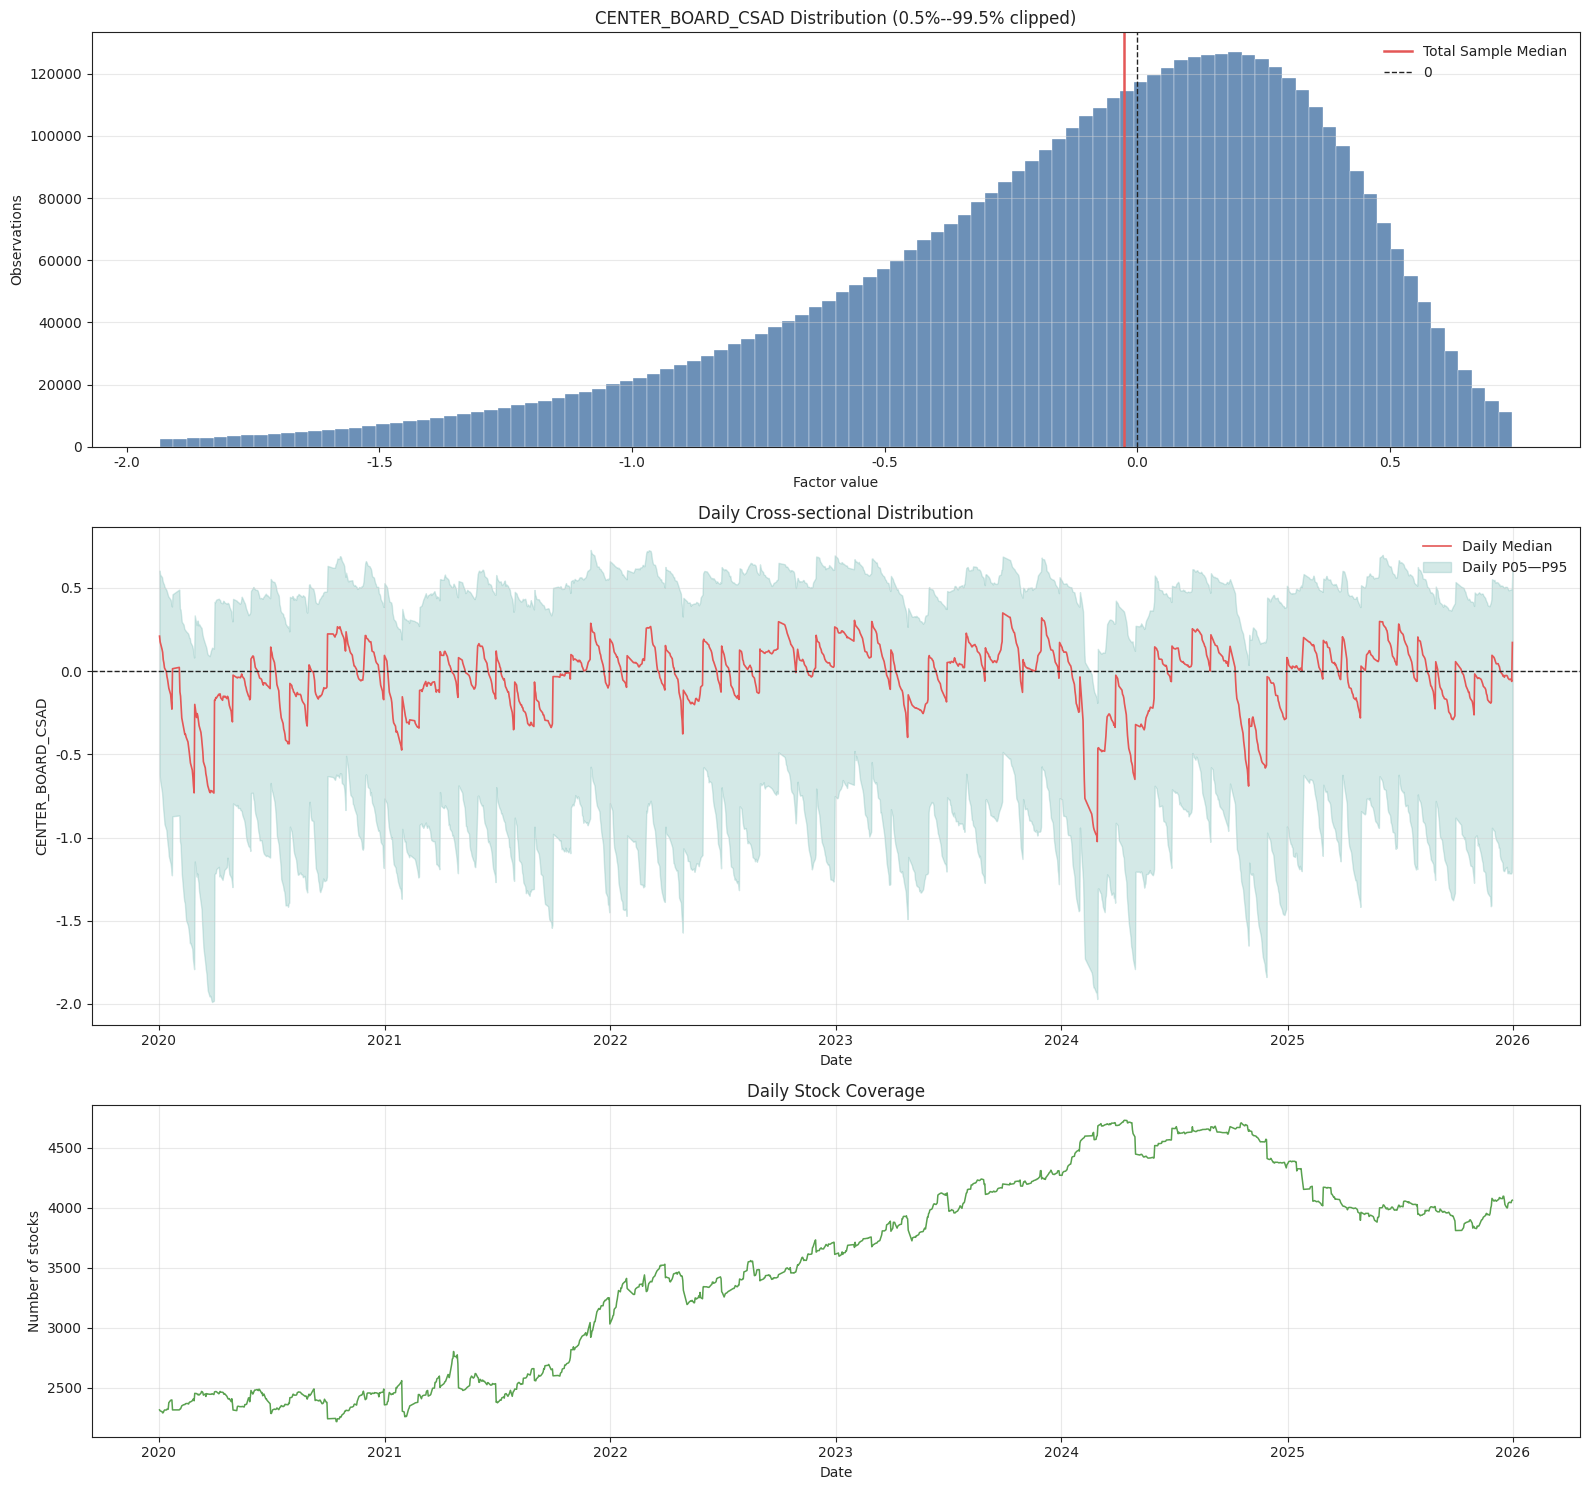

In [13]:
def plot_center_board_csad_distribution(
    panel,
    factor_name="CENTER_BOARD_CSAD",
):
    """绘制中心股票基准 CSAD 因子的分布与覆盖情况。"""

    plt.style.use("default")
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#222222",
        "axes.labelcolor": "#222222",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#222222",
        "grid.color": "#D0D0D0",
        "axes.unicode_minus": False,
        "font.family": "DejaVu Sans",
    })

    data = panel[[factor_name]].copy()
    data.index = data.index.set_names(["date", "order_book_id"])
    data = data.reset_index()

    data["date"] = pd.to_datetime(data["date"])
    data["_value"] = pd.to_numeric(
        data[factor_name],
        errors="coerce",
    )

    data = data[
        data["_value"].notna()
        & np.isfinite(data["_value"])
    ].copy()

    values = data["_value"]

    daily_q = data.groupby("date")["_value"].quantile(
        [0.05, 0.50, 0.95]
    ).unstack()

    daily_q.columns = ["P05", "Median", "P95"]

    daily_count = data.groupby("date").size().rename(
        "Number of stocks"
    )

    low = values.quantile(0.005)
    high = values.quantile(0.995)

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(16, 15),
        gridspec_kw={"height_ratios": [1.0, 1.2, 0.8]},
    )

    # 1. 全样本分布
    # clipped_values = values.clip(lower=low, upper=high)
    clipped_values = values[
        (values >= low) & (values <= high)
    ]

    axes[0].hist(
        clipped_values,
        bins=100,
        color="#4C78A8",
        alpha=0.82,
        edgecolor="white",
        linewidth=0.3,
    )

    axes[0].axvline(
        values.median(),
        color="#E45756",
        linewidth=1.8,
        label="Total Sample Median",
    )

    axes[0].axvline(
        0,
        color="#222222",
        linewidth=1.0,
        linestyle="--",
        label="0",
    )

    axes[0].set_title(
        "CENTER_BOARD_CSAD Distribution (0.5%--99.5% clipped)"
    )
    axes[0].set_xlabel("Factor value")
    axes[0].set_ylabel("Observations")
    axes[0].grid(axis="y", alpha=0.45)
    axes[0].legend(frameon=False)

    # 2. 每日横截面分布
    axes[1].fill_between(
        daily_q.index,
        daily_q["P05"],
        daily_q["P95"],
        color="#72B7B2",
        alpha=0.30,
        label="Daily P05—P95",
    )

    axes[1].plot(
        daily_q.index,
        daily_q["Median"],
        color="#E45756",
        linewidth=1.2,
        label="Daily Median",
    )

    axes[1].axhline(
        0,
        color="#222222",
        linewidth=1.0,
        linestyle="--",
    )

    axes[1].set_title("Daily Cross-sectional Distribution")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("CENTER_BOARD_CSAD")
    axes[1].grid(alpha=0.45)
    axes[1].legend(frameon=False)

    # 3. 日度覆盖股票数
    axes[2].plot(
        daily_count.index,
        daily_count.values,
        color="#59A14F",
        linewidth=1.1,
    )

    axes[2].set_title("Daily Stock Coverage")
    axes[2].set_xlabel("Date")
    axes[2].set_ylabel("Number of stocks")
    axes[2].grid(alpha=0.45)

    for ax in axes:
        for spine in ax.spines.values():
            spine.set_color("#222222")

    plt.tight_layout()
    plt.show()


plot_center_board_csad_distribution(
    center_board_csad_panel,
    factor_name="CENTER_BOARD_CSAD",
)

整体结论：该因子的数据完整性通过，数值分布也符合“中心股票相对板块偏离程度”的经济含义；但有两个需要保留的质量提示：低覆盖日，以及月末换组带来的较大机械跳变。

- 完整性完全通过：1455 个交易日均有输出，510.25 万有效观测，5325 只股票，无重复、缺失和无穷值。
- 覆盖率尚可但不完全理想：日均 3507 只股票，P05 为 2348；相对当年最高覆盖的 P05 为 76.9%，低于预设的 80% 参考线。这不代表计算错误，主要是你的规则同时要求“相关窗口内足够活跃”与“板块 10 只股票当天全部有有效收益”。但在低覆盖日做横截面选股时，应谨慎。
- 年度拼接没有断层：年度首日变化 P99 为 0.300，低于普通连续日变化 P99 的 0.435，说明按年度分别计算并未造成明显的年初跳变。
- 月末换组影响明显：月末重新选取 9 个同伴后的日变化 P99 为 1.152，约为普通连续日变化的 2.65 倍。这是月度重新构建板块带来的结构性变化，不是数值错误；但它意味着一部分信号来自“同伴集合变化”，而不仅是板块羊群状态变化。

分布也很合理：

- 均值 `-0.123`、中位数 `-0.025`，整体接近零但略偏负。
- P01 为 `-1.713`，P99 为 `0.689`，最小值 `-3.896`，最大值 `1.246`，呈明显左偏。
- 这正符合该因子的结构：CSAD 有零下界，低 CSAD 能产生的正向 Z 值有一定上限；而 CSAD 突然升高时，负向因子值可以更极端。因此“左尾更长”是合理现象，不是异常。
- `|因子值| > 3` 仅 421 条，占全部观测约 `0.008%`；不存在超过 4 的记录，极端值控制良好。
- 图中的 2020 年初、2024 年初横截面中位数明显下探，同时 P05 区间大幅向下扩张，说明许多股票相对各自板块出现了更强的收益分化。这更像市场压力期或结构性分化期，而不是单只股票异常导致。

图形有一个小的展示问题：直方图左右端的两个高柱是 `clip()` 将所有尾部观测压到边界后的人工堆积，并不代表真实的两个密度峰。将原绘图函数中的：

```python
clipped_values = values.clip(lower=low, upper=high)
```

改为：

```python
clipped_values = values[
    (values >= low) & (values <= high)
]
```

即可显示真实的截尾后分布。

最后有一个与定义更严格一致的微调建议：目前中心股票必须在月末可交易，但其余 9 个同伴只要求过去 120 日足够活跃，不强制月末当天可交易。若要严格满足“当前可交易股票”定义，将原来的 `eligible_ids` 替换为：

```python
eligible_ids = [
    stock
    for stock in valid_count[
        valid_count >= min_corr_observations
    ].index
    if pd.notna(returns.loc[rebalance_date, stock])
]
```

此外，月末形成板块时已经用了月末收盘收益；因子必须用于下一交易日。若回测程序没有统一滞后因子，请使用：

```python
center_board_csad_panel = (
    center_board_csad_panel
    .groupby(level="order_book_id")
    .shift(1)
)
```

这份结果可以进入后续 IC、分组收益和换手率检验；但建议单独比较“月末换组日”和“非月末日”的 IC，以确认收益预测能力并非主要来自换组冲击。

In [1]:
import pandas as pd
from rqfactor.notebook import factor_analysis

csv_path = "center_board_csad_panel.csv"

# 还原两层列索引；第一列还原为日期索引
raw = pd.read_csv(
    csv_path,
    header=[0, 1],
    index_col=0,
    parse_dates=True,
)

# 取出真正的 “日期 × 股票” 因子宽表
center_board_csad_factor_data = raw["CENTER_BOARD_CSAD"].copy()

# 清理数据格式
center_board_csad_factor_data.index = pd.to_datetime(
    center_board_csad_factor_data.index
)
center_board_csad_factor_data.columns = (
    center_board_csad_factor_data.columns.astype(str)
)
center_board_csad_factor_data.columns.name = "order_book_id"

center_board_csad_factor_data = (
    center_board_csad_factor_data
    .apply(pd.to_numeric, errors="coerce")
    .sort_index()
)

center_board_csad_factor_data

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688787.XSHG,688788.XSHG,688789.XSHG,688793.XSHG,688798.XSHG,688799.XSHG,688800.XSHG,688819.XSHG,688981.XSHG,689009.XSHG
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.411898,-0.388180,NaN,0.249578,0.834139,NaN,-0.177469,NaN,0.380431,0.606807,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.322883,-0.452286,NaN,0.237699,0.764870,NaN,-0.048014,NaN,0.428667,0.565456,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.367806,-0.510713,NaN,0.263799,0.748655,NaN,0.018923,NaN,0.463290,0.550881,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.415005,-0.369530,NaN,0.236151,0.694889,NaN,0.202402,NaN,0.381835,0.514836,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.347296,-0.485286,NaN,0.225074,0.688005,NaN,0.159682,NaN,0.334588,0.505669,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.090279,-0.589138,-0.462995,NaN,0.142555,-1.214911,-0.263106,0.482274,0.455278,0.448139,...,0.296728,NaN,-0.101223,-0.010879,0.196877,0.622989,-0.288581,NaN,NaN,0.095957
2025-12-26,0.044005,-0.498008,-0.362081,NaN,0.138638,-1.247507,-0.265220,0.475277,0.454288,0.456002,...,0.180005,NaN,-0.086461,-0.502120,0.210882,0.593996,-0.305684,NaN,NaN,-0.009870
2025-12-29,0.107920,-0.365254,-0.227810,NaN,0.222378,-0.889831,-0.331930,0.525470,0.452599,0.514621,...,0.196609,NaN,-0.043660,-0.468916,0.384024,0.597425,-0.299427,NaN,NaN,-0.130480


In [4]:
result_center_board_csad = factor_analysis(
    f=center_board_csad_factor_data,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=False,
    winzorization="mad",
    normalization=False,
    neutralization="none",
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

result_center_board_csad.show()

Loading BokehJS ...

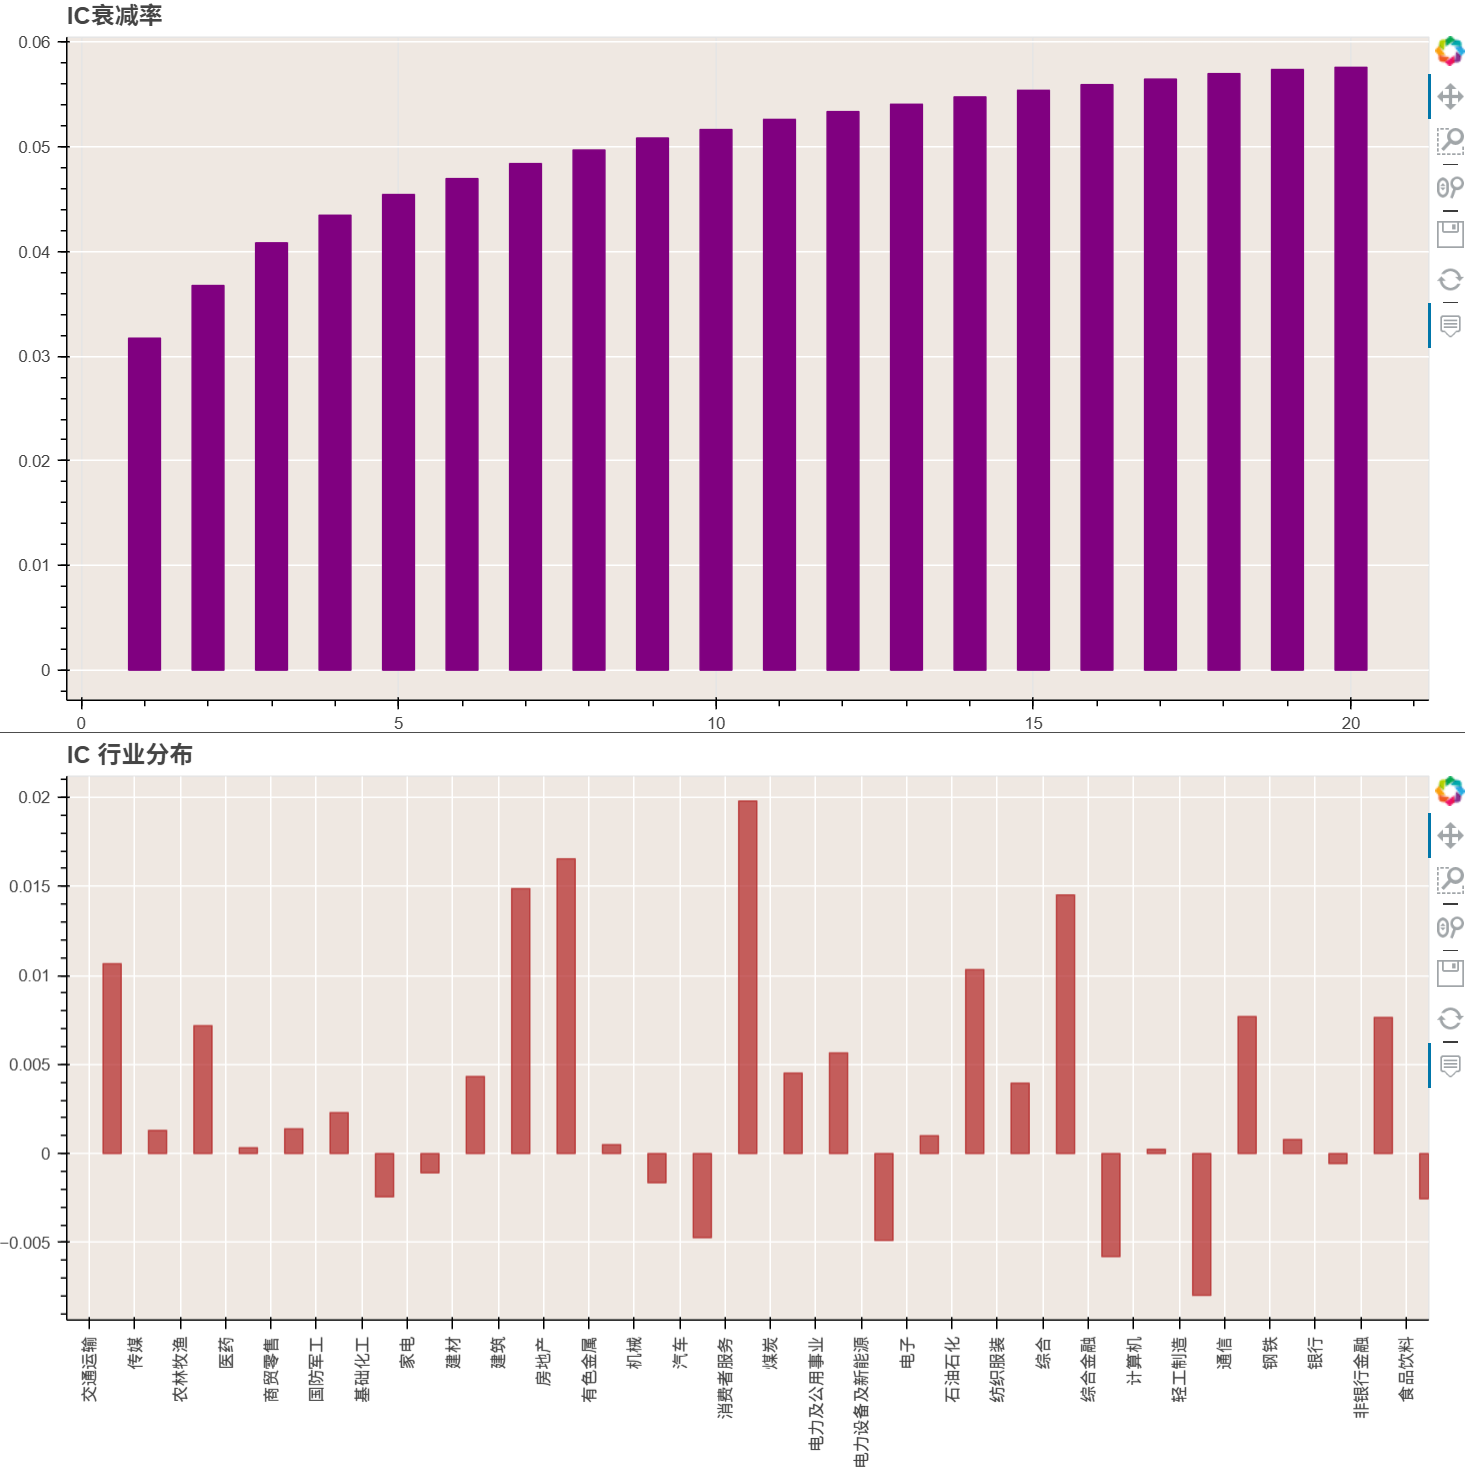

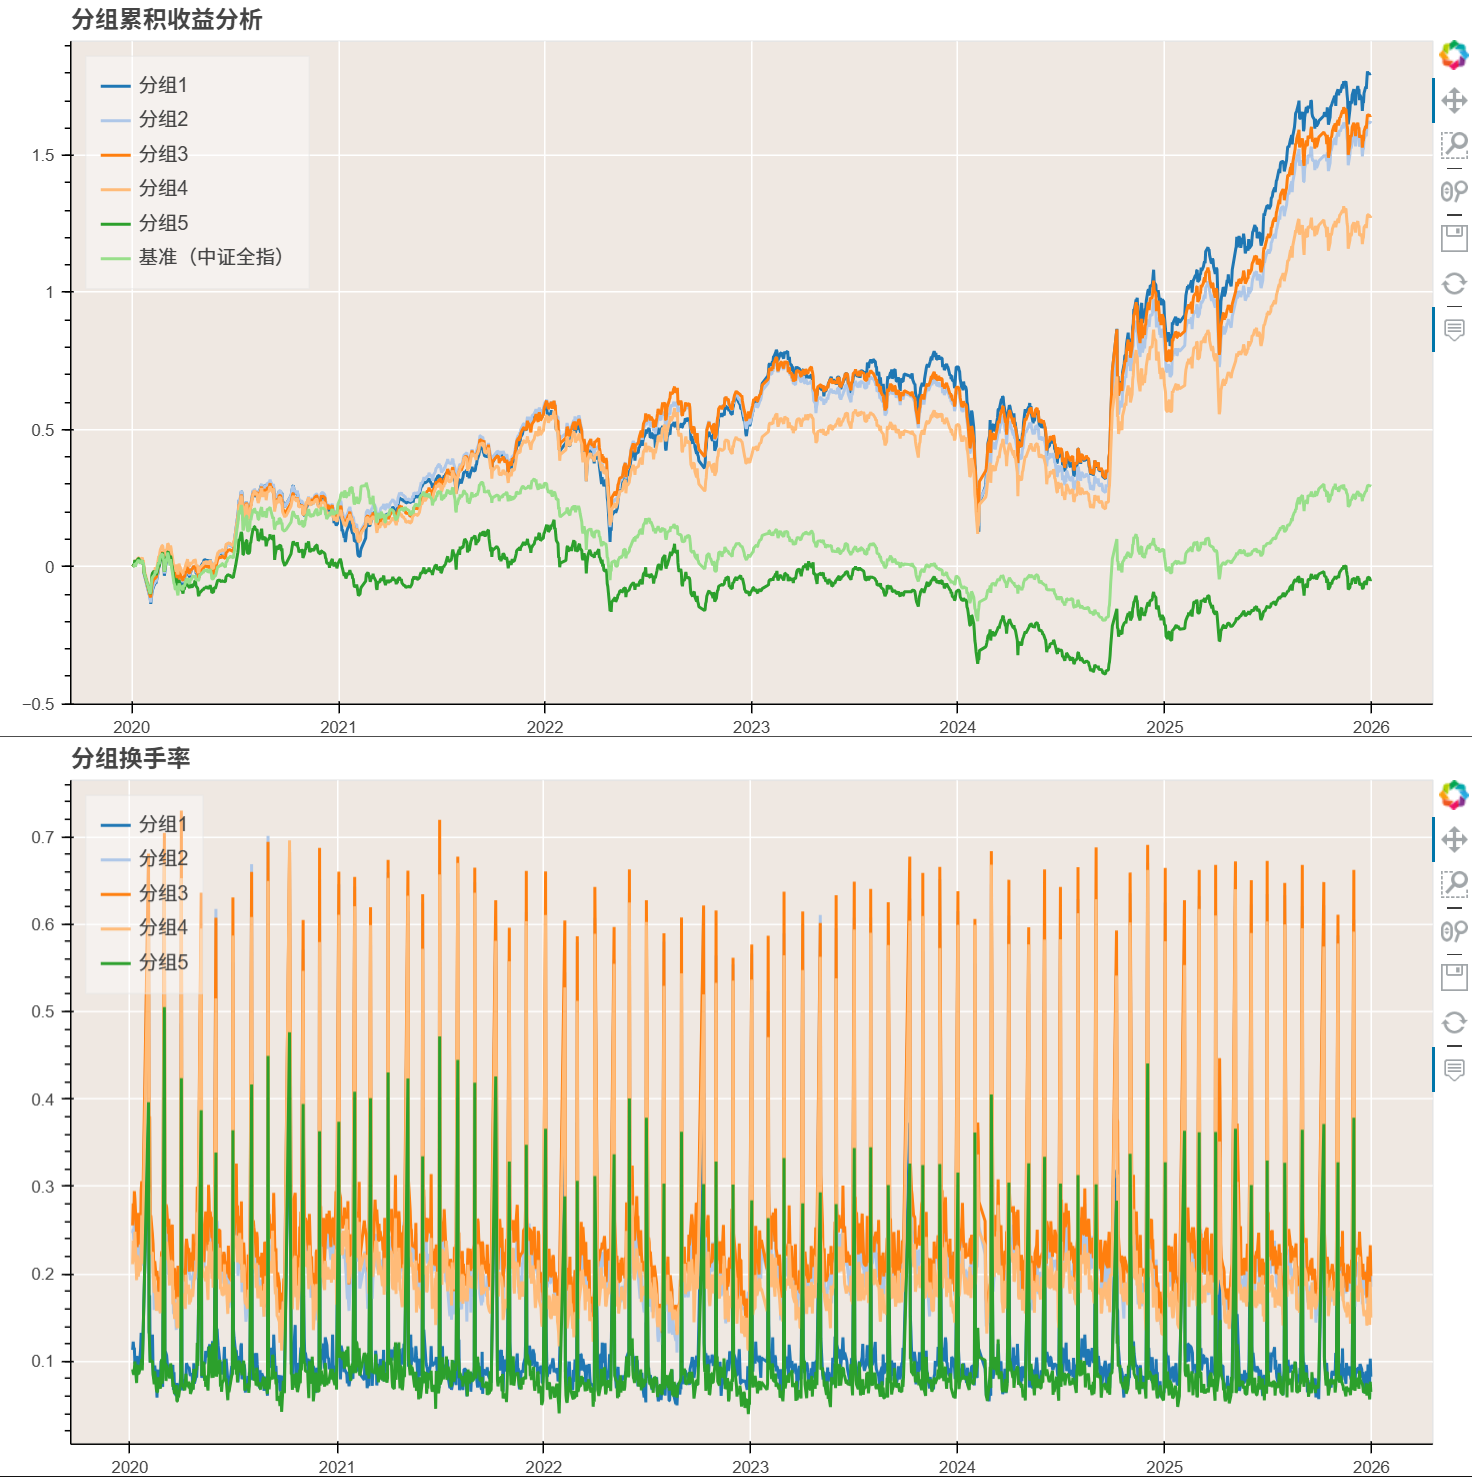

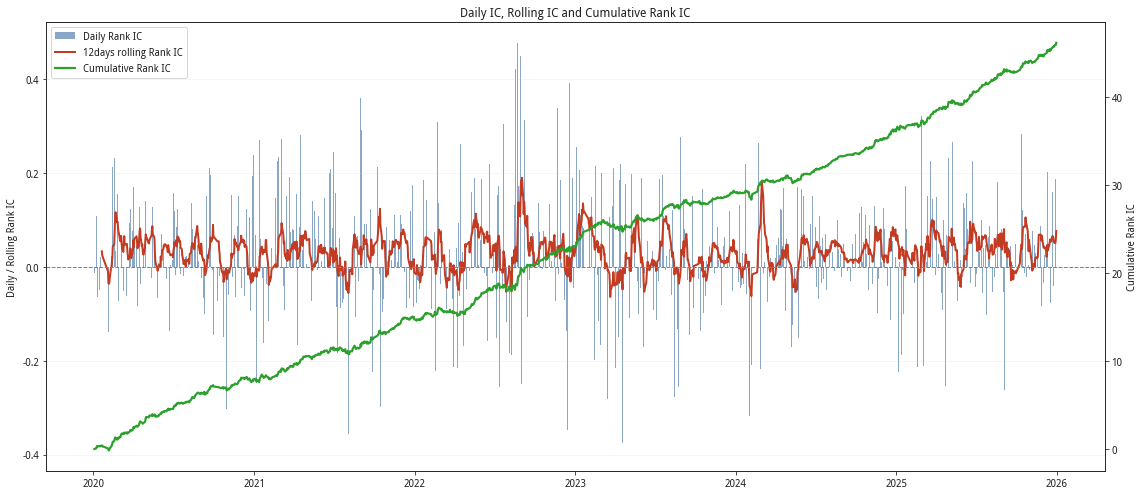

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_center_board_csad.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()